In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
df = pd.read_csv('new_netflix_customer_churn.csv')
df.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre,age_group,watch_hours_group,avg_watch_time_group
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,Yes,Gift Card,1,0.49,Action,50-100 age,0 - 25 %,50 %
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,Yes,Gift Card,5,0.03,Sci-Fi,25-49 age,0 - 25 %,min
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,No,Crypto,2,1.48,Drama,25-49 age,0 - 25 %,max
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,Yes,Crypto,2,0.35,Horror,50-100 age,0 - 25 %,50 %
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,Yes,Crypto,2,0.13,Action,50-100 age,0 - 25 %,25 %


In [15]:
total = df['customer_id'].count()
gender_count = df.groupby('gender')['gender'].count()
gender_count

gender
Female    1711
Male      1654
Other     1635
Name: gender, dtype: int64

In [16]:
churn_rate = (
    df.groupby('subscription_type')['churned']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Churn_Rate')
)


# 1. Total customer by gender

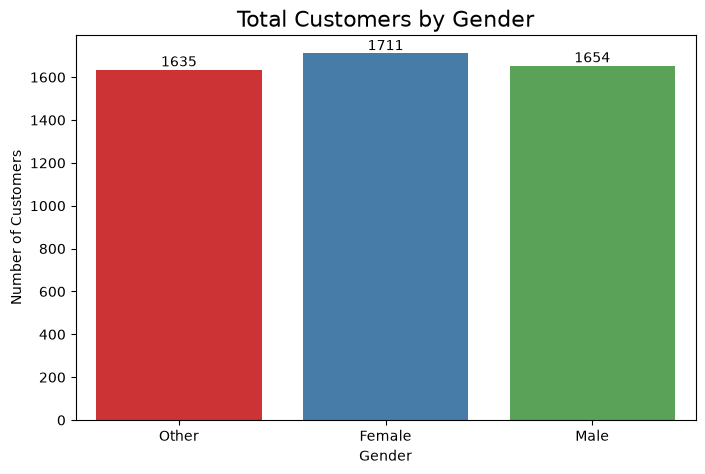

In [17]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='gender',
    hue='gender',
    palette='Set1',
    legend=False
)

plt.title('Total Customers by Gender', fontsize=16)
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

# Display count above each bar
for container in ax.containers:
    ax.bar_label(container)

plt.show()

# 1.Churn by subscription type 

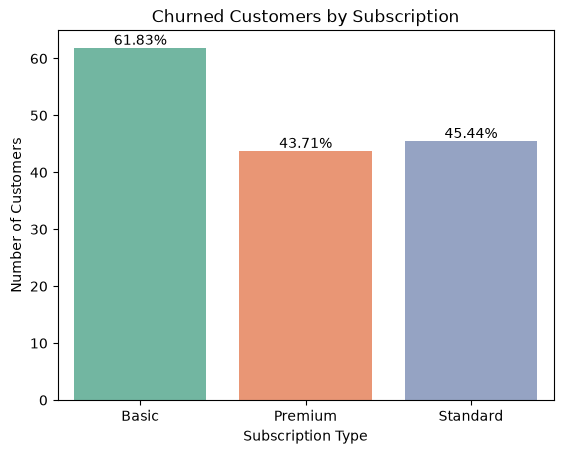

In [18]:
# 1.Churn by subscription type 

# plot 1: Churn by subscription type
ax = sns.barplot(
    data=churn_rate,
    x='subscription_type',
    y='Churn_Rate',
    hue='subscription_type',
    palette='Set2',
    legend=False
)

plt.title('Churned Customers by Subscription')
plt.xlabel('Subscription Type')
plt.ylabel('Number of Customers')


for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')

plt.show()


# watch_hours vs churn

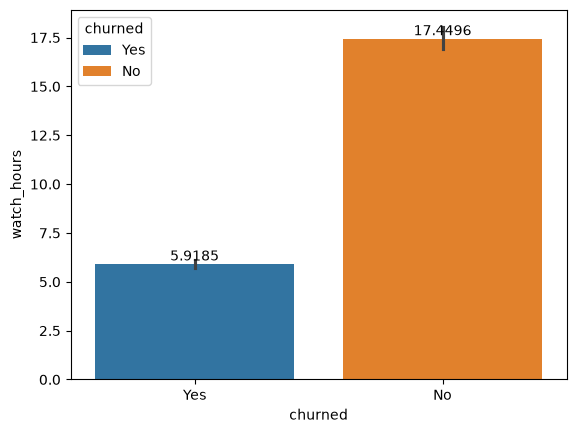

In [19]:
# plot 1: using bar plot
ax = sns.barplot(
    data = df,
    x = 'churned',
    y = 'watch_hours',
    hue = 'churned',
    legend = True
)

for container in ax.containers:
    ax.bar_label(container)

plt.show()

# Churn by subscription & device

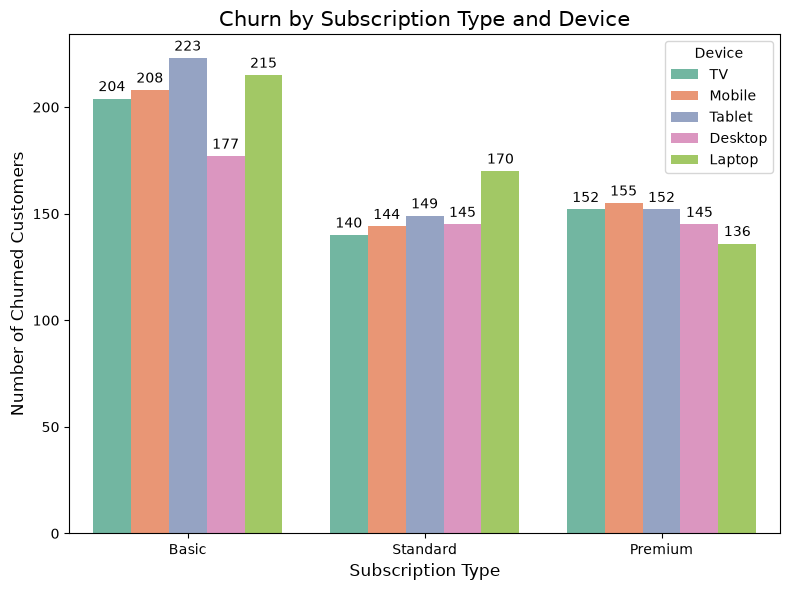

In [20]:
# Filter churned customers
churn_data = df[df['churned'] == 'Yes']

# Create grouped bar chart
plt.figure(figsize=(8, 6))

ax = sns.countplot(
    data=churn_data,
    x='subscription_type',
    hue='device',
    palette='Set2'
)

# Add title and labels
plt.title('Churn by Subscription Type and Device', fontsize=15)
plt.xlabel('Subscription Type', fontsize=12)
plt.ylabel('Number of Churned Customers', fontsize=12)

# Add count labels above bars
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.legend(title='Device')
plt.tight_layout()
plt.show()

# churn and total customer by region

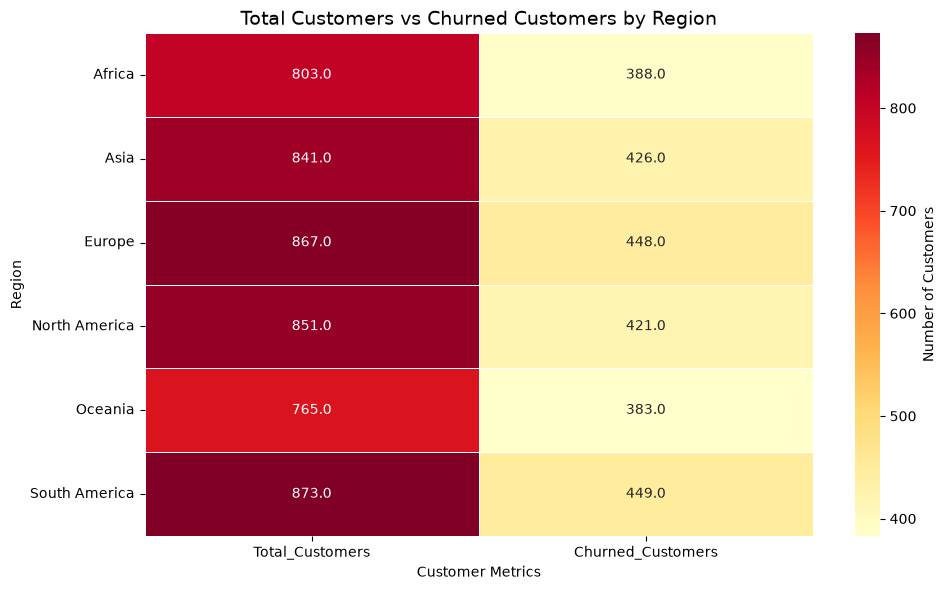

In [21]:
region_analysis = df.groupby('region').agg(
     Total_Customers=('customer_id', 'count'),
     Churned_Customers=('churned', lambda x: (x == 'Yes').sum())
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    region_analysis[['Total_Customers', 'Churned_Customers']],
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Number of Customers'}
)

plt.title('Total Customers vs Churned Customers by Region', fontsize=14)
plt.xlabel('Customer Metrics')
plt.ylabel('Region')

plt.tight_layout()
plt.show()

# churn by age_group, fees, genre

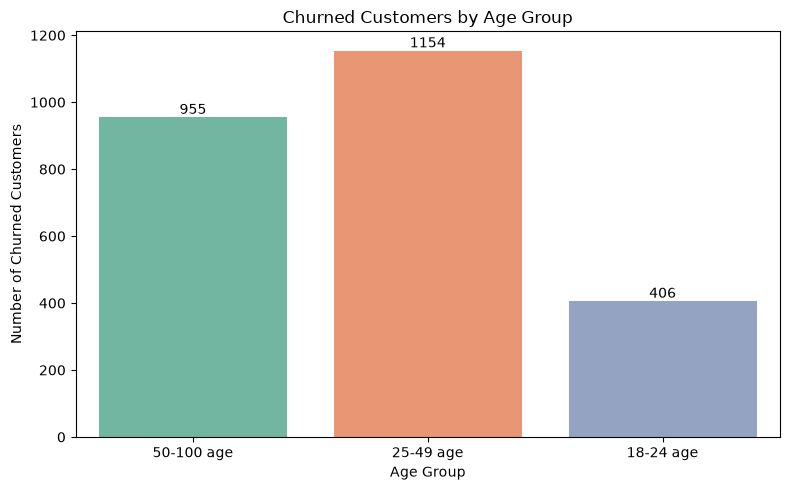

In [22]:
# Churn by age_group

churn_data = df[df['churned'] == 'Yes']
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=churn_data,
    x='age_group',
    hue='age_group',
    palette='Set2',
    legend=False
)

plt.title('Churned Customers by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Churned Customers')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

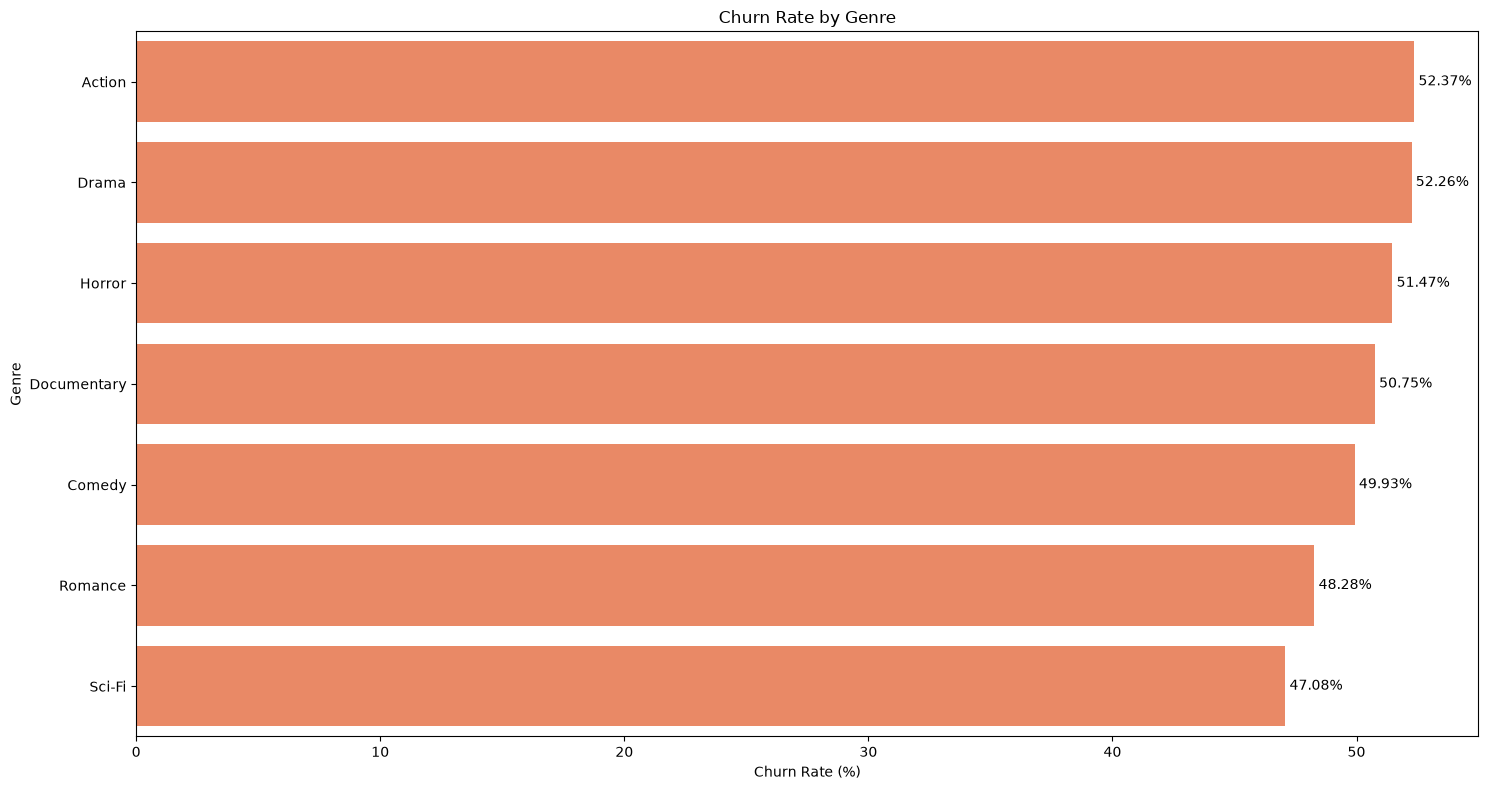

In [23]:
# churn by genre

genre_churn = (
    df.groupby('favorite_genre')['churned']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(15, 8))

ax = sns.barplot(
    x=genre_churn.values,
    y=genre_churn.index,
    color = 'coral'
)

plt.title('Churn Rate by Genre')
plt.xlabel('Churn Rate (%)')
plt.ylabel('Genre')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.tight_layout()
plt.show()


# number_of_profiles vs churned

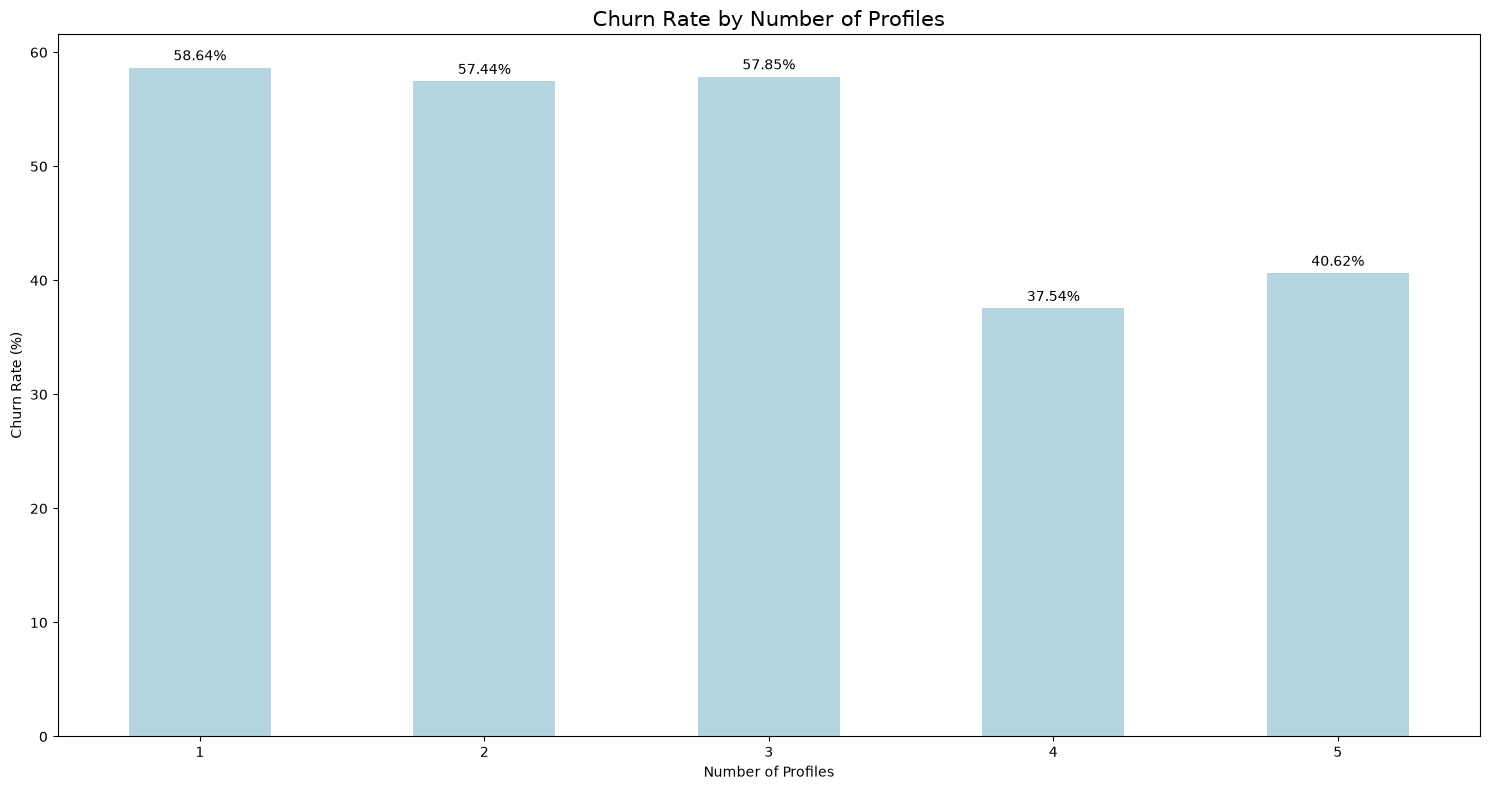

In [27]:
profile_churn = (
    df.groupby('number_of_profiles')['churned']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='Churn_Rate')
)
plt.figure(figsize=(15, 8))
ax = sns.barplot(
    data=profile_churn,
    x='number_of_profiles',
    y='Churn_Rate',
    color= 'lightblue',
    width = 0.5
)

plt.title('Churn Rate by Number of Profiles', fontsize=15)
plt.xlabel('Number of Profiles')
plt.ylabel('Churn Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)
plt.tight_layout()
plt.show()